# Seaborn: Practical Examples

This notebook demonstrates common Seaborn plots with locally generated data. It does not need to download example datasets.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
print("Seaborn:", sns.__version__)

Seaborn: 0.13.2


## 1. Build a sample dataset

In [2]:
rng = np.random.default_rng(42)
n = 60
students = pd.DataFrame({
    "group": np.repeat(["A", "B", "C"], n // 3),
    "study_hours": rng.uniform(1, 10, n).round(1),
    "attendance": rng.integers(60, 101, n),
})
group_bonus = students["group"].map({"A": 0, "B": 4, "C": 7})
students["score"] = (45 + students["study_hours"] * 4 + group_bonus
                     + rng.normal(0, 7, n)).clip(0, 100).round(1)
students.head()

,group,study_hours,attendance,score
0,A,8.0,78,80.4
1,A,4.9,87,67.7
2,A,8.7,86,84.5
3,A,7.3,79,73.5
4,A,1.8,95,49.2


## 2. Scatter plot with hue and style

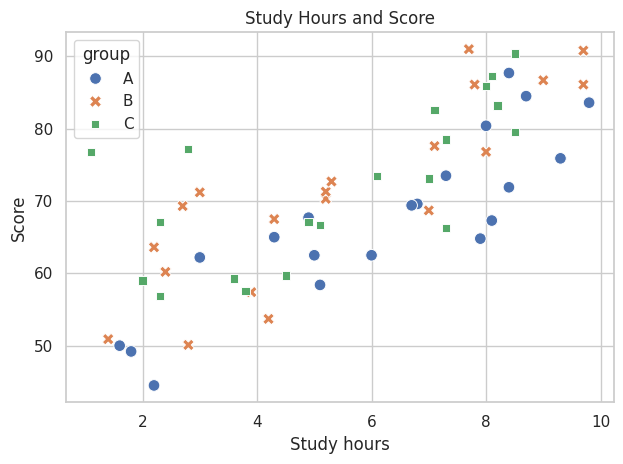

In [3]:
ax = sns.scatterplot(
    data=students, x="study_hours", y="score",
    hue="group", style="group", s=70
)
ax.set(title="Study Hours and Score", xlabel="Study hours", ylabel="Score")
plt.tight_layout()
plt.show()

## 3. Line plot

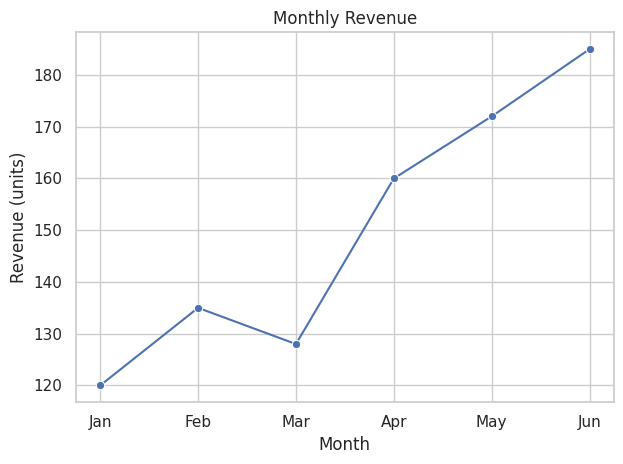

In [4]:
monthly = pd.DataFrame({
    "month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
    "revenue": [120, 135, 128, 160, 172, 185]
})
sns.lineplot(data=monthly, x="month", y="revenue", marker="o", errorbar=None)
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (units)")
plt.tight_layout()
plt.show()

## 4. Distribution plots: histogram, KDE, and ECDF

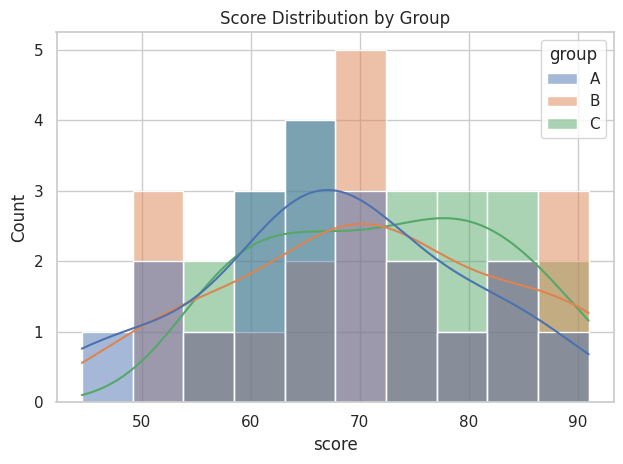

In [5]:
sns.histplot(data=students, x="score", hue="group", bins=10, kde=True)
plt.title("Score Distribution by Group")
plt.tight_layout()
plt.show()

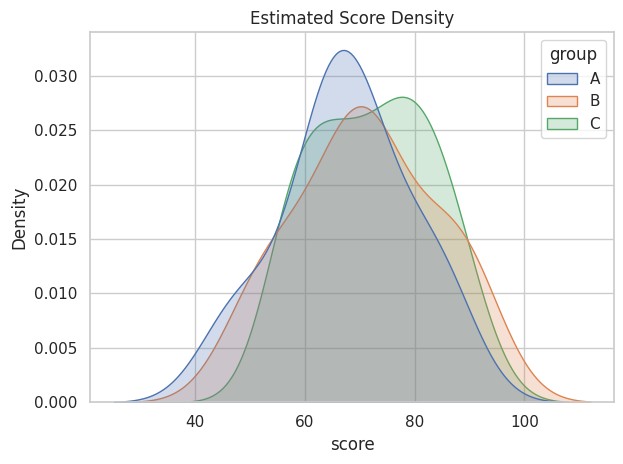

In [6]:
sns.kdeplot(data=students, x="score", hue="group", fill=True, common_norm=False)
plt.title("Estimated Score Density")
plt.tight_layout()
plt.show()

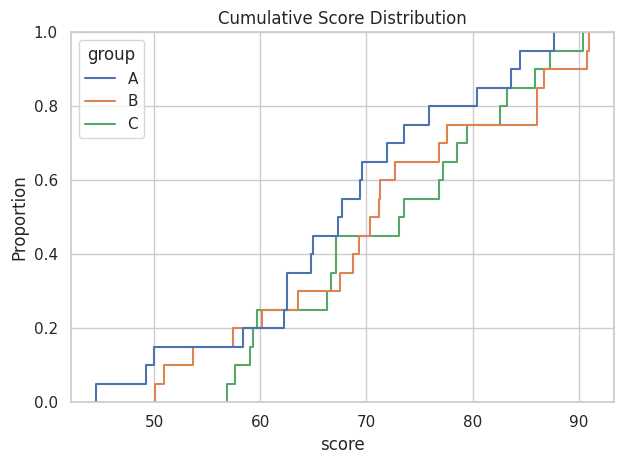

In [7]:
sns.ecdfplot(data=students, x="score", hue="group")
plt.title("Cumulative Score Distribution")
plt.tight_layout()
plt.show()

## 5. Categorical comparisons

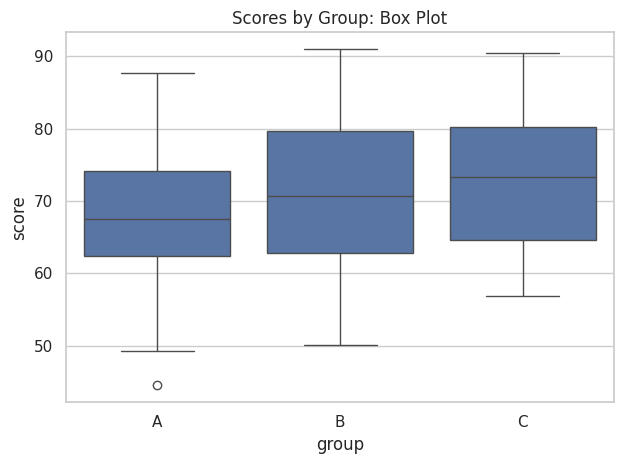

In [8]:
sns.boxplot(data=students, x="group", y="score")
plt.title("Scores by Group: Box Plot")
plt.tight_layout()
plt.show()

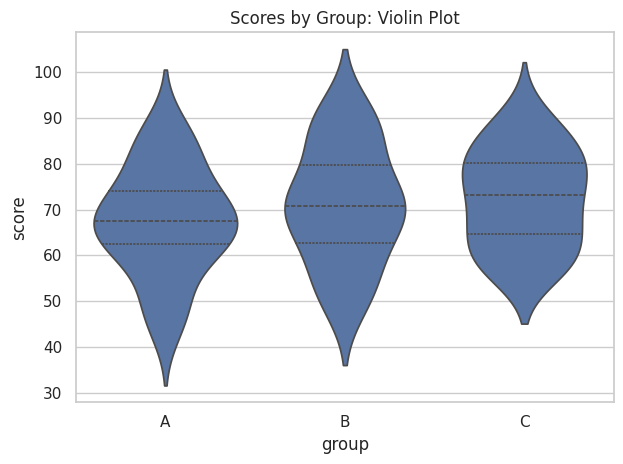

In [9]:
sns.violinplot(data=students, x="group", y="score", inner="quart")
plt.title("Scores by Group: Violin Plot")
plt.tight_layout()
plt.show()

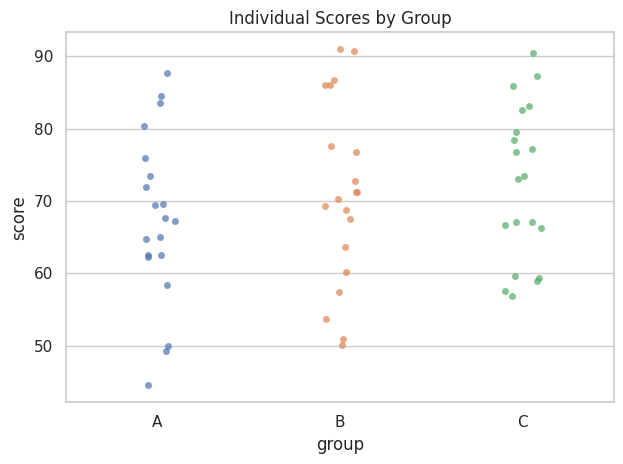

In [10]:
sns.stripplot(data=students, x="group", y="score", jitter=True, alpha=0.7)
plt.title("Individual Scores by Group")
plt.tight_layout()
plt.show()

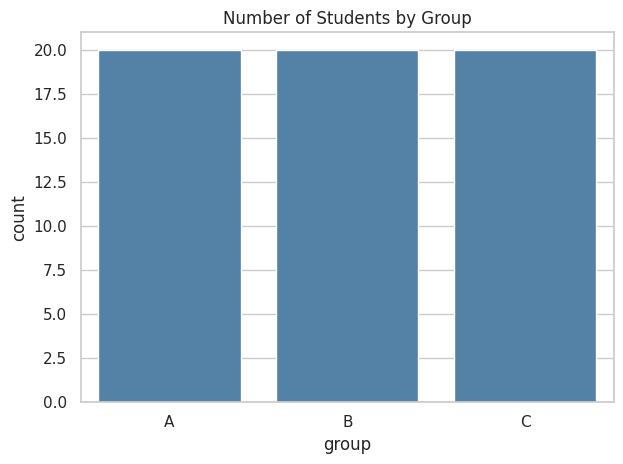

In [11]:
sns.countplot(data=students, x="group", color="steelblue")
plt.title("Number of Students by Group")
plt.tight_layout()
plt.show()

## 6. Faceting with relplot

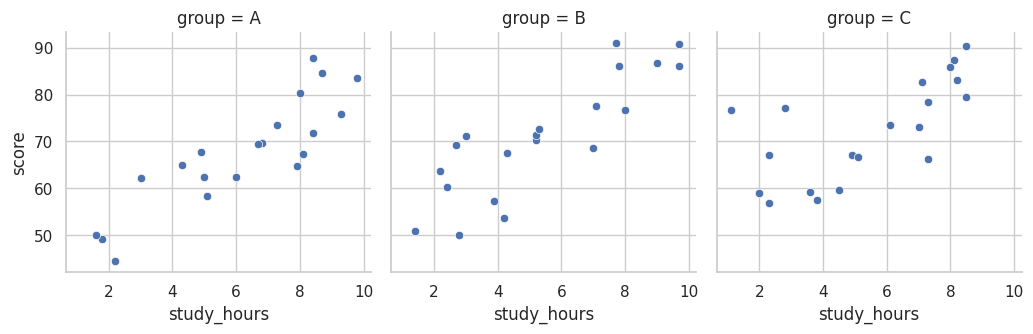

In [12]:
sns.relplot(
    data=students, x="study_hours", y="score",
    col="group", kind="scatter", height=3.5
)
plt.show()

## 7. Correlation heatmap

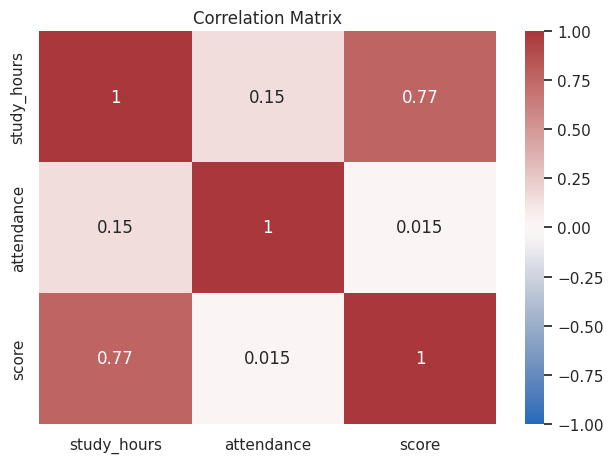

In [13]:
correlation = students[["study_hours", "attendance", "score"]].corr()
sns.heatmap(correlation, annot=True, vmin=-1, vmax=1, cmap="vlag")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## 8. Regression plot

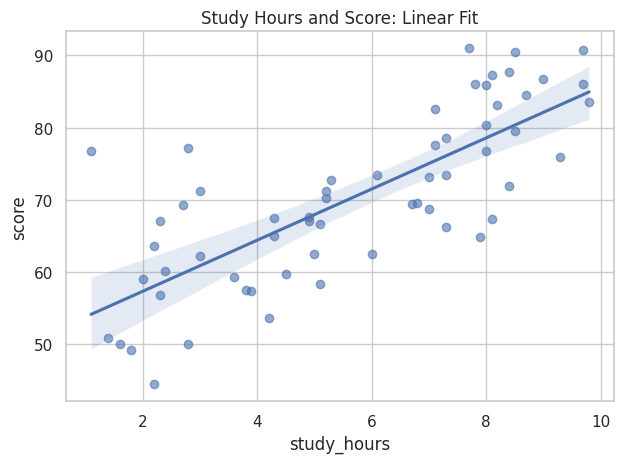

In [14]:
sns.regplot(data=students, x="study_hours", y="score",
            scatter_kws={"alpha": 0.6})
plt.title("Study Hours and Score: Linear Fit")
plt.tight_layout()
plt.show()

## 9. Theme and palette

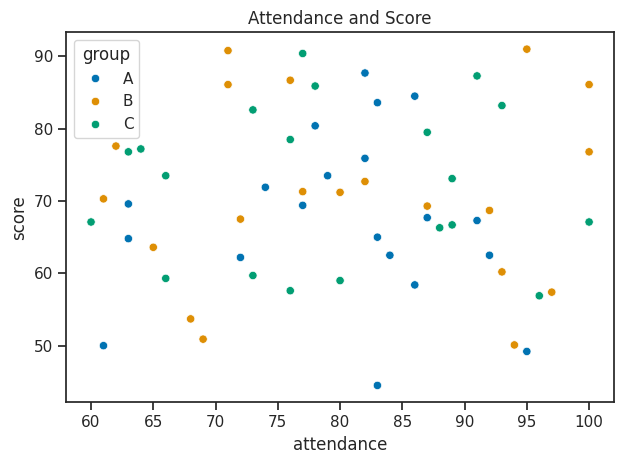

In [15]:
sns.set_theme(style="ticks", palette="colorblind")
sns.scatterplot(data=students, x="attendance", y="score", hue="group")
plt.title("Attendance and Score")
plt.tight_layout()
plt.show()

## 10. Mini-project prompts

1. Compare score distributions across groups with box and violin plots.
2. Use a scatter plot to explore study hours versus score.
3. Add attendance as a visual grouping or facet.
4. Create a correlation heatmap for numeric columns.
5. Write three observations and two limitations. Association does not establish causation.